In [1]:
%matplotlib ipympl

from ipywidgets import *

import sys
from time import time
import itertools
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colormaps
from mpl_toolkits.mplot3d import Axes3D, art3d

from pathlib import Path

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 75

import xml.etree.ElementTree as ET
import h5py
import utils

from importlib import reload

sys.path.append('/Users/patrickoare/lqcd/utilities')
# import pytools as pyt
import plottools as pt
import formattools as fmt
pt.set_font()
default_style = fmt.styles['notebook']
default_style['colwidth'] = 15

# import utils
import matplotlib.animation as animation

In [2]:
# palette = sns.color_palette('cubehelix', n_colors = Nk)
palette = pt.pal
sty = default_style.copy()
sty['asp_ratio'] = 1.5
sty['colwidth'] = 12
sty['fontsize'] = 36

nbsty = sty.copy()
nbsty['colwidth'] = 8
nbsty['fontsize'] = 24

In [3]:
# Write figures to this directory
FIGS_DIR = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/Wilson_Spectrum/Figures'

# Topology change with Krylov-Schur

Ritz values on $D_W$ with HKS are copied locally at `/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702_2` with each folder named `U_smr_${tau}` for a given value of $\tau$. Each of these subdirectories contain `eval_cmplx.100`, which is the Ritz value result after 100 iterations of HKS. Some of the subdirectories also contain `eval_cmplx.1000`, which is the result after 1000 iterations of HKS. The 1000 iteration result is obviously much more accurate than the 100 iteration result, it just takes longer to run so there are a smaller number of 1000-iteration results.

### $\tau$ near $3.0$

In [4]:
reload(fmt)

<module 'formattools' from '/Users/patrickoare/lqcd/utilities/formattools.py'>

In [5]:
sty = fmt.styles['prd_twocol*']
sty['markersize'] = 10.

In [6]:
dir702 = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702_2'
base = Path(dir702)
taus = sorted(
    (d.name.removeprefix("U_smr_") for d in base.glob("U_smr_*") if d.is_dir()),
    key=float,
)

evals = {}
for tau in taus:
    evals[tau] = utils.read_chulwoo_file(f'{dir702}/U_smr_{tau}/eval_cmplx.100')

In [7]:
tau0 = '3.000000'           # reference tau for comparison
taus_plot = [
    '3.000000',
    '3.012500',
    '3.025000',
    '3.037500',
    '3.050000',
    '3.062500',
    '3.075000',
    '3.087500',
    '3.100000',
    '3.112500',
]
taus_plot_trim = [
    '3.0000',
    '3.0125',
    '3.0250',
    '3.0375',
    '3.0500',
    '3.0625',
    '3.0750',
    '3.0875',
    '3.1000',
    '3.1125',
]

In [8]:
# eval_path = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/complex_evals/U_smr_'

# taus = [
#     '3.000000',
#     '3.012500',
#     '3.025000',
#     '3.037500',
#     '3.050000',
#     '3.062500',
#     '3.075000',
#     '3.087500',
#     '3.100000',
#     '3.112500',
# ]

# taus_trimmed = [
#     '3.0000',
#     '3.0125',
#     '3.0250',
#     '3.0375',
#     '3.0500',
#     '3.0625',
#     '3.0750',
#     '3.0875',
#     '3.1000',
#     '3.1125',
# ]

# evals = {}
# for tau in taus:
#     evals[tau] = utils.read_chulwoo_file(f'{eval_path}{tau}')

(<Figure size 487.5x365.625 with 1 Axes>,
 <Axes: xlabel='$\\mathbb{R}[\\lambda]$', ylabel='$\\mathbb{I}[\\lambda]$'>)

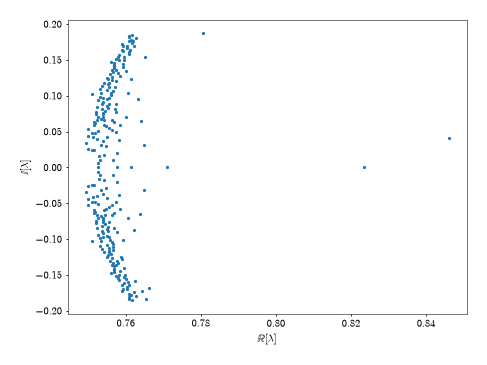

In [9]:
pt.scatter_1d(np.real(evals[tau0]), np.imag(evals[tau0]), col = pt.pal[0], ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], style = sty)

In [10]:
# pt.scatter_1d(np.real(evals[taus[0]]), np.imag(evals[taus[0]]), col = pt.pal[0], ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], style = sty)

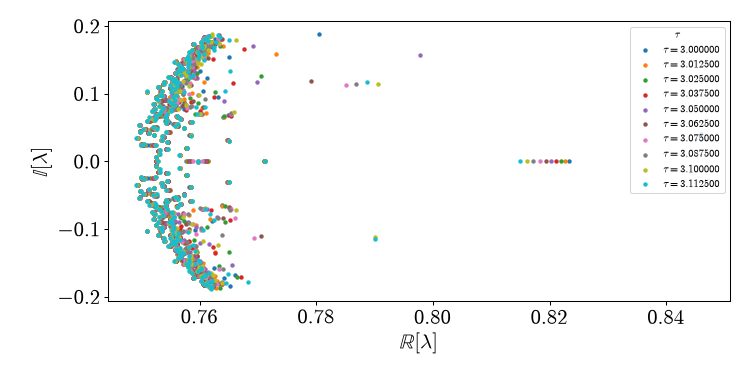

In [11]:
fig, axes = pt.add_subplots()
ax = axes[0]
# for idx, tau in enumerate(taus):
for idx, tau in enumerate(taus_plot):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = pt.pal[idx], fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])
# plt.legend(title = r'$\tau$', fontsize = default_style['fontsize'])
plt.legend(title = r'$\tau$')

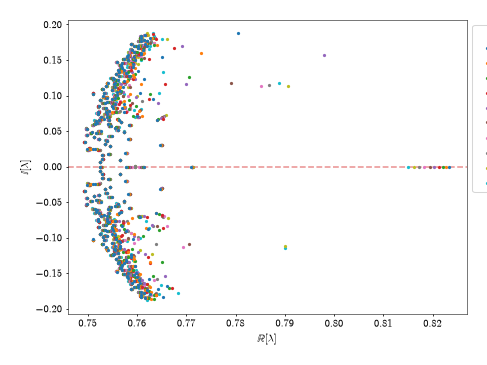

In [12]:
# TODO: change zord so first evals are layered last?
# sty['markersize'] = 80
fig, axes = pt.add_subplots(style = sty)
ax = axes[0]
pt.add_line(ax, val = 0, orientation = 'h', color = pt.pal[3], alpha = 0.5, linestyle = 'dashed', zorder = -100)
# for idx, tau in enumerate(taus):
for idx, tau in enumerate(taus_plot):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = pt.pal[idx], fn_label = r'$\tau = ' + taus_plot_trim[idx] + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], zorder=-idx, style = sty)
plt.legend(title = r'$\tau$', fontsize = sty['fontsize'], title_fontsize = sty['fontsize'], bbox_to_anchor = (1, 1), ncols = 1)
ax.set_xlim((0.746, 0.827))
plt.savefig(f'{FIGS_DIR}/wilson_evals_leg.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

In [13]:
reload(fmt)

<module 'formattools' from '/Users/patrickoare/lqcd/utilities/formattools.py'>

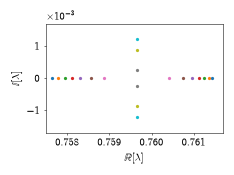

In [14]:
zoom_sty = fmt.styles['prd_twocol']
zoom_sty['markersize'] = 10
fig, axes = pt.add_subplots(style = zoom_sty)
ax = axes[0]
# pt.add_line(ax, val = 0, orientation = 'h', color = pt.pal[3], alpha = 0.5, linestyle = 'dashed', zorder = -1)
for idx, tau in enumerate(taus_plot):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = pt.pal[idx], fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], style = zoom_sty)
ax.set_xlim((0.7575, 0.7617))
ax.set_ylim((-0.0017, 0.0017))
ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, -3), useMathText=True)
ax.yaxis.get_offset_text().set_fontsize(zoom_sty['fontsize'])
plt.tight_layout()
# plt.savefig(f'{FIGS_DIR}/wilson_evals_zoomed.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])#, pad_inches = 0.05)

### $\tau$ near 3.95

In [15]:
tau1 = '3.950000'           # reference tau for comparison

(<Figure size 487.5x365.625 with 1 Axes>,
 <Axes: xlabel='$\\mathbb{R}[\\lambda]$', ylabel='$\\mathbb{I}[\\lambda]$'>)

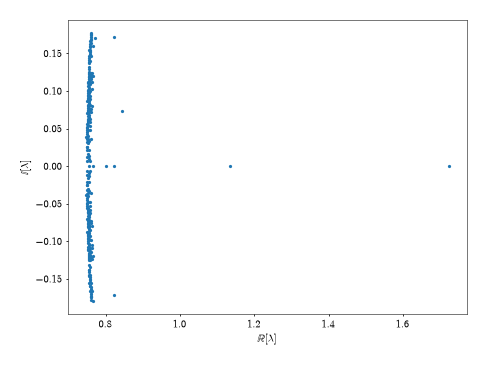

In [16]:
pt.scatter_1d(np.real(evals[tau1]), np.imag(evals[tau1]), col = pt.pal[0], ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], style = sty)

In [17]:
taus_plot = [
    '3.937500',
    '3.943750',
    '3.950000',
    '3.956250',
    '3.962500',
]
# taus_plot_trim = [
#     '3.9500',
# ]

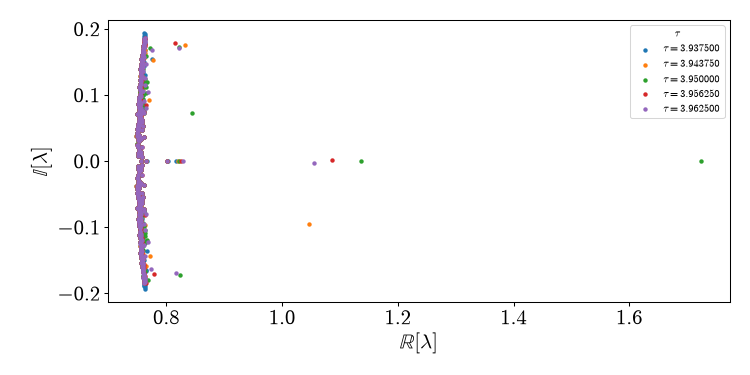

In [18]:
fig, axes = pt.add_subplots()
ax = axes[0]
# for idx, tau in enumerate(taus):
for idx, tau in enumerate(taus_plot):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = pt.pal[idx], fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])
# plt.legend(title = r'$\tau$', fontsize = default_style['fontsize'])
# ax.set_xlim((0.74, 0.85))
plt.legend(title = r'$\tau$')

## All taus between 3.0 and 4.0 after 100 iterations

Note that all this data is with 100 iterations, so many Ritz values may not yet be converged. There are many more configurations ($> 200$) with this data run, but it is less precise.

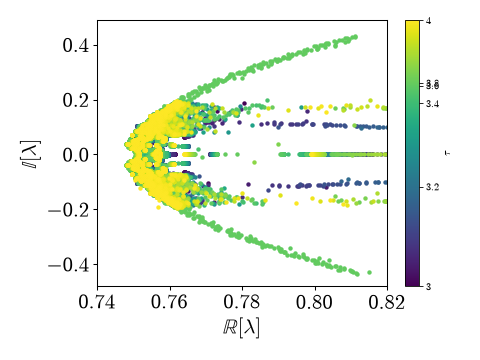

In [19]:
taus34 = [t for t in taus if 3.0 <= float(t) <= 4.0]

cmap = mpl.colormaps["viridis"]
norm = mpl.colors.Normalize(vmin=0, vmax=len(taus34) - 1)

fig, ax = plt.subplots()
for i, tau in enumerate(taus34):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

ax.set_xlim((0.74, 0.82))

# TODO relabel
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

tick_taus = ['3.000000', '3.200000', '3.400000', '3.600000', '3.800000', '4.000000']
cbar.set_ticks([taus34.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

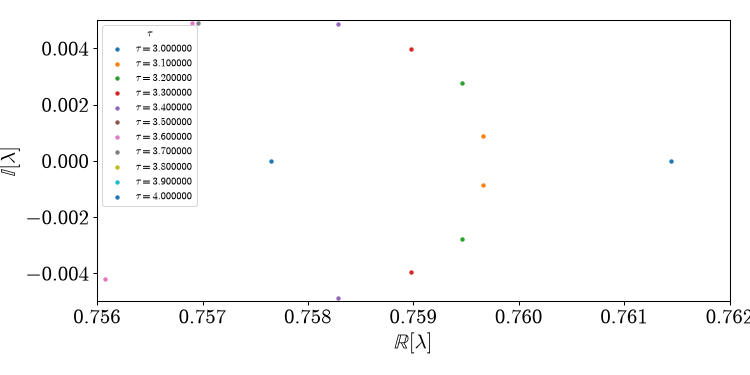

In [20]:
taus_plot = [
    '3.000000',
    '3.100000',
    '3.200000',
    '3.300000',
    '3.400000',
    '3.500000',
    '3.600000',
    '3.700000',
    '3.800000',
    '3.900000',
    '4.000000',
]

fig, axes = pt.add_subplots()
ax = axes[0]
for idx, tau in enumerate(taus_plot):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = pt.pal[idx % len(pt.pal)], fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])
# ax.set_xlim((0.74, 0.9))
ax.set_xlim((0.756, 0.762))
ax.set_ylim((-0.005, 0.005))
plt.legend(title = r'$\tau$')

#### Event 1: Collision around $z=0.76$

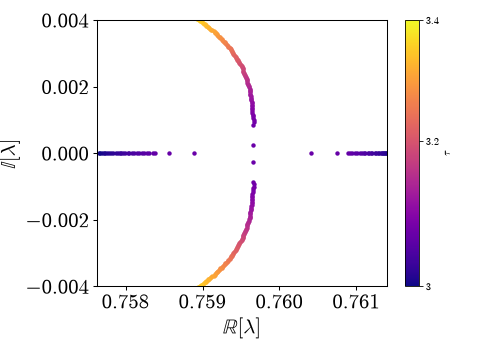

In [21]:
tau_window = [t for t in taus if 3.0 <= float(t) <= 3.4]

# cmap = mpl.colormaps['magma']
cmap = mpl.colormaps['plasma']
norm = mpl.colors.Normalize(vmin=0, vmax=len(tau_window) - 1)
# norm = mpl.colors.PowerNorm(gamma=0.5, vmin=0, vmax=len(tau_window) - 1)

fig, ax = plt.subplots()
for i, tau in enumerate(tau_window):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.757, 0.762))
ax.set_xlim((0.75763, 0.7614))
ax.set_ylim((-0.004, 0.004))

# TODO relabel
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

tick_taus = ['3.000000', '3.200000', '3.400000']
cbar.set_ticks([tau_window.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# plt.savefig(f'{FIGS_DIR}/event1.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

#### Event 2: Collision around $z=0.88$

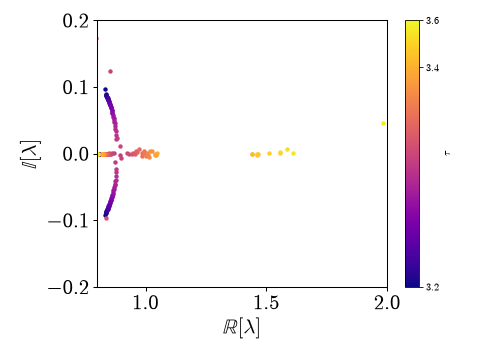

In [22]:
tau_window1 = [t for t in taus if 3.20 <= float(t) <= 3.60]

# cmap = mpl.colormaps['magma']
cmap = mpl.colormaps['plasma']
norm = mpl.colors.Normalize(vmin=0, vmax=len(tau_window1) - 1)
# norm = mpl.colors.PowerNorm(gamma=0.5, vmin=0, vmax=len(tau_window1) - 1)

fig, ax = plt.subplots()
for i, tau in enumerate(tau_window1):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.82, 1.5))
ax.set_xlim((0.8, 2))
ax.set_ylim((-0.2, 0.2))

# TODO relabel
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

tick_taus = ['3.200000', '3.400000', '3.600000']
cbar.set_ticks([tau_window1.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# plt.savefig(f'{FIGS_DIR}/event2.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

## All taus between 3.0 and 4.0 after 1000 iterations

The Ritz values are much more likely to be converged here, but there are less configurations to analyze. 

In [23]:
evals_1000 = {}
taus_1000 = []
for tau in taus:
    try:
        evals_1000[tau] = utils.read_chulwoo_file(f'{dir702}/U_smr_{tau}/eval_cmplx.1000')
        taus_1000.append(tau)
    except:
        pass

In [24]:
taus_1000

['0.00000',
 '3.275000',
 '3.281250',
 '3.287500',
 '3.293750',
 '3.300000',
 '3.400000',
 '3.800000',
 '3.900000',
 '3.925000',
 '3.927083',
 '3.931250',
 '3.937500',
 '3.950000',
 '3.975000',
 '3.987500']

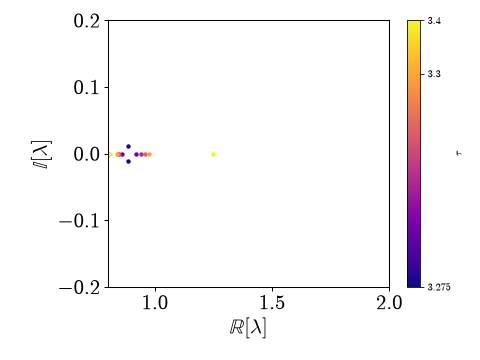

In [25]:
tau_window1 = [t for t in taus_1000 if 3.20 <= float(t) <= 3.60]

# cmap = mpl.colormaps['magma']
cmap = mpl.colormaps['plasma']
norm = mpl.colors.Normalize(vmin=0, vmax=len(tau_window1) - 1)
# norm = mpl.colors.PowerNorm(gamma=0.5, vmin=0, vmax=len(tau_window1) - 1)

fig, ax = plt.subplots()
for i, tau in enumerate(tau_window1):
    pt.scatter_1d(np.real(evals_1000[tau]), np.imag(evals_1000[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.82, 1.5))
ax.set_xlim((0.8, 2))
ax.set_ylim((-0.2, 0.2))

# TODO relabel
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

tick_taus = ['3.275000', '3.300000', '3.400000']
cbar.set_ticks([tau_window1.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# plt.savefig(f'{FIGS_DIR}/event2.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

# Spectral Flow

Spectral flow data will be stored locally at `/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702`. 

In [26]:
reload(utils)

<module 'utils' from '/Users/patrickoare/lqcd/multigrid/python_scripts/utils.py'>

In [27]:
specflow_dir = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702'
# specflow_dir = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702_3'

base_sf = Path(specflow_dir)
taus_sf = sorted(
    (d.name.removeprefix("U_smr_") for d in base_sf.glob("U_smr_*") if d.is_dir()),
    key=float,
)

masses_sf = {}
evals_sf = {}
dmu_sf = {}
for tau in taus_sf:
    tmp = utils.read_specflow_input(f'{specflow_dir}/U_smr_{tau}/eval.dat')
    masses_sf[tau] = tmp[0]
    evals_sf[tau] = tmp[1]
    dmu_sf[tau] = tmp[2]

In [28]:
taus_sf

['0.000000',
 '0.100000',
 '0.200000',
 '0.300000',
 '0.400000',
 '0.500000',
 '0.600000',
 '0.700000',
 '0.800000',
 '0.900000',
 '1.000000',
 '1.100000',
 '1.200000',
 '1.300000',
 '1.400000',
 '1.500000',
 '1.600000',
 '1.700000',
 '1.800000',
 '1.900000',
 '2.000000',
 '2.100000',
 '2.200000',
 '2.300000',
 '2.400000',
 '2.500000',
 '2.600000',
 '2.700000',
 '2.800000',
 '2.900000',
 '3.000000',
 '3.100000',
 '3.200000',
 '3.250000',
 '3.300000',
 '3.350000',
 '3.400000',
 '3.450000',
 '3.456250',
 '3.468750',
 '3.475000',
 '3.481250',
 '3.487500',
 '3.493750',
 '3.500000',
 '3.550000',
 '3.600000',
 '3.700000',
 '3.800000',
 '3.900000',
 '3.931250',
 '3.937500',
 '3.943750',
 '3.950000',
 '3.956250',
 '3.968750',
 '4.000000']

In [29]:
# tau0_sf = '3.300000'

# fig, ax = plt.subplots()
# for idx, sf_eval_branch in enumerate(evals_sf[tau0_sf]):
#     pt.scatter_1d(-masses_sf[tau0_sf], sf_eval_branch, ax = ax, col = pt.pal[0], ax_label = [r'$m$', r'$\lambda(m)$'])

# ax.set_xlim((0.7, 0.9))
# ax.set_ylim((-0.02, 0.02))
# # plt.legend()

In [30]:
# tau0_sf = '3.300000'
# # delta = 0.002                                  # half-length of each tangent
# delta = 0.0025                                  # half-length of each tangent
# lam = -masses_sf[tau0_sf]
# nan = np.full_like(lam, np.nan)

# fig, ax = plt.subplots()
# for sf_eval_branch, sf_dmu_branch in zip(evals_sf[tau0_sf], dmu_sf[tau0_sf]):
#     pt.scatter_1d(lam, sf_eval_branch, ax = ax, col = pt.pal[0], ax_label = [r'$m$', r'$\lambda(m)$'])
#     # tangent through each point; the slope in lam = -m is -dmu/dm
#     ax.plot(np.stack([lam - delta, lam + delta, nan], -1).ravel(),
#             np.stack([sf_eval_branch + delta * sf_dmu_branch, sf_eval_branch - delta * sf_dmu_branch, nan], -1).ravel(),
#             ':', color = pt.pal[0])

# ax.axhline(0, color = 'k', lw = 0.8)
# ax.set_xlim((0.7, 0.9))
# ax.set_ylim((-0.02, 0.02))

In [31]:
# tau_plot = ['3.250000', '3.300000', '3.350000', '3.400000', '3.450000', '3.500000']

# delta = 0.0025                                  # half-length of each tangent
# fig, ax = plt.subplots()
# for idx, tau_sf in enumerate(tau_plot):
#     lam = -masses_sf[tau_sf]
#     nan = np.full_like(lam, np.nan)

#     for sf_eval_branch, sf_dmu_branch in zip(evals_sf[tau_sf], dmu_sf[tau_sf]):
#         pt.scatter_1d(lam, sf_eval_branch, ax = ax, col = pt.pal[idx], ax_label = [r'$m$', r'$\lambda(m)$'], fn_label = tau_sf)
#         # tangent through each point; the slope in lam = -m is -dmu/dm
#         ax.plot(np.stack([lam - delta, lam + delta, nan], -1).ravel(),
#                 np.stack([sf_eval_branch + delta * sf_dmu_branch, sf_eval_branch - delta * sf_dmu_branch, nan], -1).ravel(),
#                 ':', color = pt.pal[idx])

# ax.axhline(0, color = 'k', lw = 0.8)
# # ax.set_xlim((0.7, 0.9))
# ax.set_xlim((0.7, 1.5))
# ax.set_ylim((-0.02, 0.02))

# handles, labels = ax.get_legend_handles_labels()
# unique = dict(zip(labels, handles))                # later duplicates overwrite earlier ones
# ax.legend(unique.values(), unique.keys(), title = r'$\tau$')
# ax.set_title('Event 1')
# # ax.legend()

In [32]:
def plot_specflow(ax, tau_plot, xlims = None, ylims = None, title = None, cmap = pt.pal, delta = 0.0025, legend = True, dash = False):
    for idx, tau_sf in enumerate(tau_plot):
        lam = -masses_sf[tau_sf]
        nan = np.full_like(lam, np.nan)

        for sf_eval_branch, sf_dmu_branch in zip(evals_sf[tau_sf], dmu_sf[tau_sf]):
            pt.scatter_1d(lam, sf_eval_branch, ax = ax, col = cmap[idx], ax_label = [r'$m$', r'$\lambda(m)$'], fn_label = tau_sf)
            # tangent through each point; the slope in lam = -m is -dmu/dm
            ax.plot(np.stack([lam - delta, lam + delta, nan], -1).ravel(),
                    np.stack([sf_eval_branch + delta * sf_dmu_branch, sf_eval_branch - delta * sf_dmu_branch, nan], -1).ravel(),
                    ':', color = cmap[idx])

    if dash:
        ax.axhline(0, color = 'k', linestyle = '--', lw = 0.8)
    else:
        ax.axhline(0, color = 'k', lw = 0.8)
    if xlims:    
        ax.set_xlim(xlims)
    if ylims:
        ax.set_ylim(ylims)

    if legend:
        handles, labels = ax.get_legend_handles_labels()
        unique = dict(zip(labels, handles))                # later duplicates overwrite earlier ones
        ax.legend(unique.values(), unique.keys(), title = r'$\tau$', loc = 'upper right')
    if title:
        ax.set_title(title)

    return

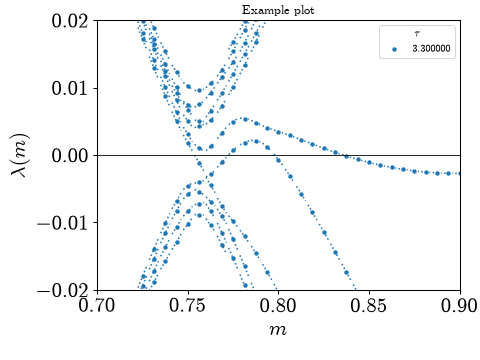

In [33]:
fig, ax = plt.subplots()
plot_specflow(ax, ['3.300000'], xlims = (0.7, 0.9), ylims = (-0.02, 0.02), title = 'Example plot')

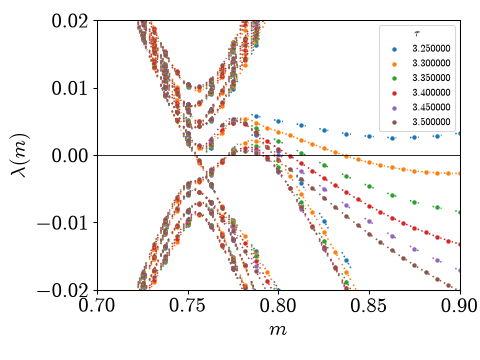

In [34]:
tau_plot = ['3.250000', '3.300000', '3.350000', '3.400000', '3.450000', '3.500000']
fig, ax = plt.subplots()
plot_specflow(ax, tau_plot, xlims = (0.7, 0.9), ylims = (-0.02, 0.02))

# Topology change events

We have 2 events of interest, and one precursor event (cc pair collision) that is not clear if it comes from a topology change event or not. This is all done with $M_5 = 1.8$ as the threshold. 
1. Collision at $\tau\approx 3.28$ at $z\approx 0.86$, crosses $M_5$ around $\tau\approx 3.486$.
2. Collision at $\tau\approx 3.929$ at $z\approx 1.40$, crosses $M_5$ around $\tau\approx 3.959$.
3. Collision at $\tau\approx 3.08$, $z = 0.76$. Unknown if this is the the result of a topology change or not: the eigenvalues are real and then move off the axis, so we would have to probe $\tau < 3.08$ with a finer resolution.

Currently evidence of topology change is coming from spectral flow, but Chulwoo is running the HKS to see the eigenvalue trajectory more precisely. 

### Event 1: $\tau\in [3.2, 3.5]$

In [35]:
tau_window1 = [t for t in taus if 3.20 <= float(t) <= 3.50]

tau_all = np.array(tau_window1, dtype=float)
N = len(tau_all)                      # 79
cmap = mpl.colormaps['plasma']
norm = mpl.colors.Normalize(vmin=0, vmax=len(tau_window1) - 1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

tau_coarse = np.round(np.arange(3.2, 3.5 + 1e-9, 0.05), 6)
idx_coarse = np.interp(tau_coarse, tau_all, np.arange(N))
colors_coarse = cmap(idx_coarse / (N - 1))   # same scale as cmap(idx / (N - 1))

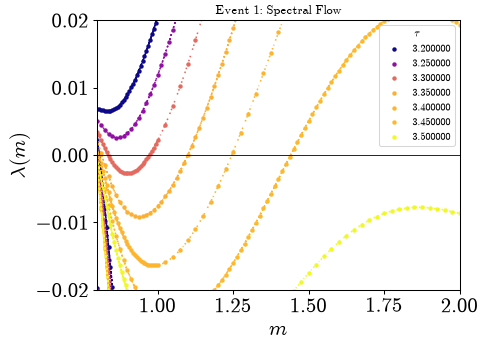

In [36]:
tau_plot = ['3.200000', '3.250000', '3.300000', '3.350000', '3.400000', '3.450000', '3.500000']
cmap_discrete = []
fig, ax = plt.subplots()
plot_specflow(ax, tau_plot, xlims = (0.8, 2.0), ylims = (-0.02, 0.02), title = r'Event 1: Spectral Flow', cmap = colors_coarse, delta = 0.01)

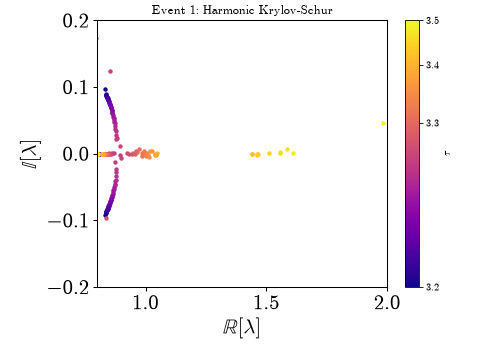

In [37]:
fig, ax = plt.subplots()
for i, tau in enumerate(tau_window1):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.82, 1.5))
ax.set_xlim((0.8, 2))
ax.set_ylim((-0.2, 0.2))
ax.set_title(r'Event 1: Harmonic Krylov-Schur',)

cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

# tick_taus = ['3.200000', '3.400000', '3.600000']
tick_taus = ['3.200000', '3.300000', '3.400000', '3.500000']
cbar.set_ticks([tau_window1.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# plt.savefig(f'{FIGS_DIR}/event2.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

/Users/patrickoare/lqcd/utilities/plottools.py:344: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(
/Users/patrickoare/lqcd/utilities/plottools.py:350: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


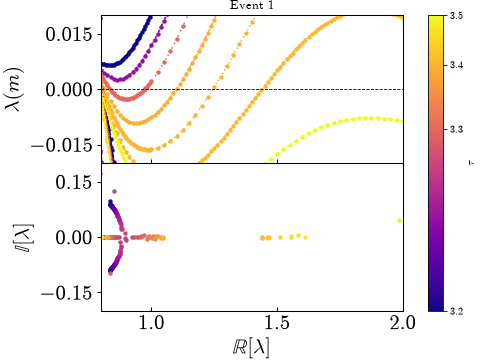

In [38]:
hspace = 0.001

# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw = {'hspace': 0.00})
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, layout='constrained')
fig.get_layout_engine().set(hspace=hspace, h_pad=0)

tau_plot = ['3.200000', '3.250000', '3.300000', '3.350000', '3.400000', '3.450000', '3.500000']
cmap_discrete = []
plot_specflow(ax1, tau_plot, xlims = (0.8, 2.0), ylims = (-0.02, 0.02), title = r'Event 1: Spectral Flow', cmap = colors_coarse, delta = 0.01, legend = False, dash = True)

for i, tau in enumerate(tau_window1):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax2, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

fig.set_layout_engine('constrained')
fig.get_layout_engine().set(hspace=hspace, h_pad=0)

# ax.set_xlim((0.82, 1.5))
ax2.set_xlim((0.8, 2))
ax2.set_ylim((-0.2, 0.2))
# ax1.set_title(r'Event 1',)
ax1.set_title('Event 1')

# cbar = fig.colorbar(sm, ax=ax2, label=r"$\tau$")
cbar = fig.colorbar(sm, ax=[ax1, ax2], label=r"$\tau$", pad = 0.02)

# tick_taus = ['3.200000', '3.400000', '3.600000']
tick_taus = ['3.200000', '3.300000', '3.400000', '3.500000']
cbar.set_ticks([tau_window1.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# from matplotlib.ticker import MaxNLocator
# ax2.yaxis.set_major_locator(MaxNLocator(prune='upper'))   # drop ax2's top label

# ax1.tick_params(axis='x', bottom=True, labelbottom=False)

ax1.set_xlabel('')

ax1.set_yticks([-0.015, 0, 0.015])
ax2.set_yticks([-0.15, 0, 0.15])

# ax1.label_outer()
# ax1.tick_params(axis='x', bottom=True, labelbottom=False)
# ax2.tick_params(axis='x', bottom=True, labelbottom=True)

for ax in (ax1, ax2):
    ax.tick_params(axis='x', which='both', direction='in', bottom=True, top=False)
ax1.tick_params(axis='x', labelbottom=False)

# plt.savefig(f'{FIGS_DIR}/event2.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

### Event 2: $\tau\in [3.9, 4.0]$

In [39]:
tau_window2 = [t for t in taus if 3.9 <= float(t) <= 4.0]
tau_all2 = np.array([t for t in taus if 3.9 <= float(t) <= 4.0], dtype=float)
N = len(tau_all2)
norm = mpl.colors.Normalize(vmin=0, vmax=N - 1)

tau_coarse2 = np.array(['3.900000', '3.931250', '3.937500', '3.943750',
                        '3.950000', '3.956250', '3.968750', '4.000000'], dtype=float)
idx_coarse2 = np.interp(tau_coarse2, tau_all2, np.arange(N))
colors_coarse2 = cmap(norm(idx_coarse2))      # 8 colors

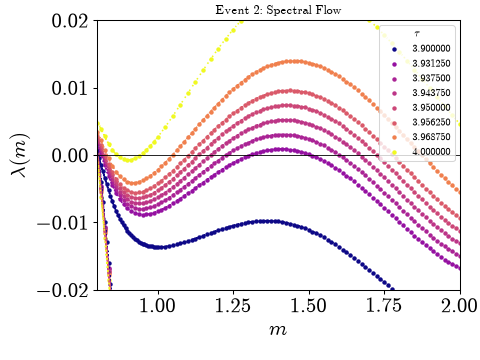

In [40]:
tau_plot2 = [f'{t:.6f}' for t in tau_coarse2]      # string keys into the spectral flow dicts
fig, ax = plt.subplots()
plot_specflow(ax, tau_plot2, xlims = (0.8, 2.0), ylims = (-0.02, 0.02), title = r'Event 2: Spectral Flow', cmap = colors_coarse2, delta = 0.01)

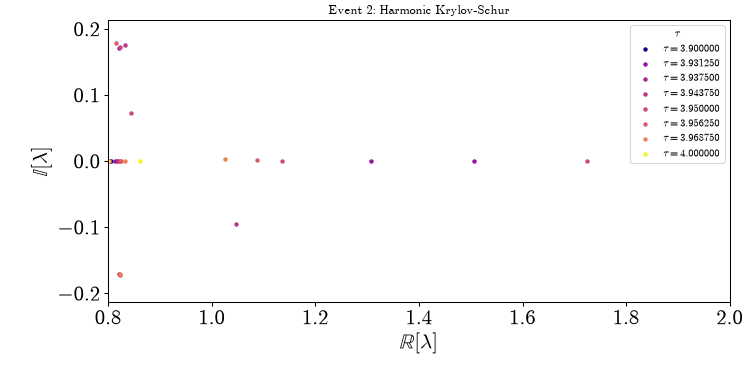

In [41]:
fig, axes = pt.add_subplots()
ax = axes[0]
for tau, col in zip(tau_plot2, colors_coarse2):      # same taus and colors as the spectral flow plot
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = col, fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])
# plt.legend(title = r'$\tau$', fontsize = default_style['fontsize'])
ax.set_xlim((0.8, 2.0))
ax.set_title(r'Event 2: Harmonic Krylov-Schur')
plt.legend(title = r'$\tau$')

/Users/patrickoare/lqcd/utilities/plottools.py:344: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(
/Users/patrickoare/lqcd/utilities/plottools.py:350: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


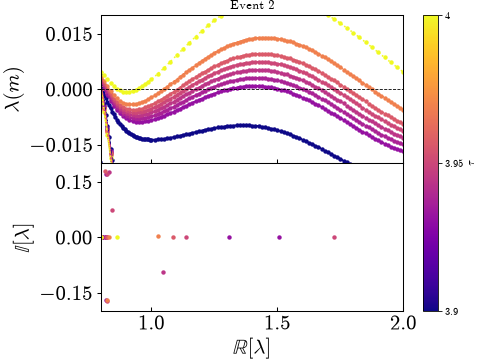

In [42]:
hspace = 0.001
N2 = len(tau_window2)
norm2 = mpl.colors.Normalize(vmin=0, vmax=N2 - 1)
sm2 = mpl.cm.ScalarMappable(norm=norm2, cmap=cmap)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, layout='constrained')
fig.get_layout_engine().set(hspace=hspace, h_pad=0)

tau_plot2 = [f'{t:.6f}' for t in tau_coarse2]      # string keys into the spectral flow dicts
cmap_discrete = []
plot_specflow(ax1, tau_plot2, xlims = (0.8, 2.0), ylims = (-0.02, 0.02), title = r'Event 2: Spectral Flow', cmap = colors_coarse2, delta = 0.01, legend = False, dash = True)

for tau, col in zip(tau_plot2, colors_coarse2):      # same taus and colors as the spectral flow plot
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax2, col = col, fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

fig.set_layout_engine('constrained')
fig.get_layout_engine().set(hspace=hspace, h_pad=0)

# ax.set_xlim((0.82, 1.5))
ax2.set_xlim((0.8, 2))
ax2.set_ylim((-0.2, 0.2))
ax1.set_title('Event 2')

# cbar = fig.colorbar(sm, ax=[ax1, ax2], label=r"$\tau$", pad = 0.02)
cbar = fig.colorbar(sm2, ax=[ax1, ax2], label=r"$\tau$", pad=0.02)

tick_taus = ['3.900000', '3.950000', '4.000000']
cbar.set_ticks([tau_window2.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

ax1.set_xlabel('')

ax1.set_yticks([-0.015, 0, 0.015])
ax2.set_yticks([-0.15, 0, 0.15])

for ax in (ax1, ax2):
    ax.tick_params(axis='x', which='both', direction='in', bottom=True, top=False)
ax1.tick_params(axis='x', labelbottom=False)

# plt.savefig(f'{FIGS_DIR}/event2.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

(<Figure size 750x375 with 1 Axes>,
 <Axes: title={'center': '$\\tau = 3.95$ (rerun by Chulwoo this week until convergence)'}, xlabel='$\\mathbb{R}[\\lambda]$', ylabel='$\\mathbb{I}[\\lambda]$'>)

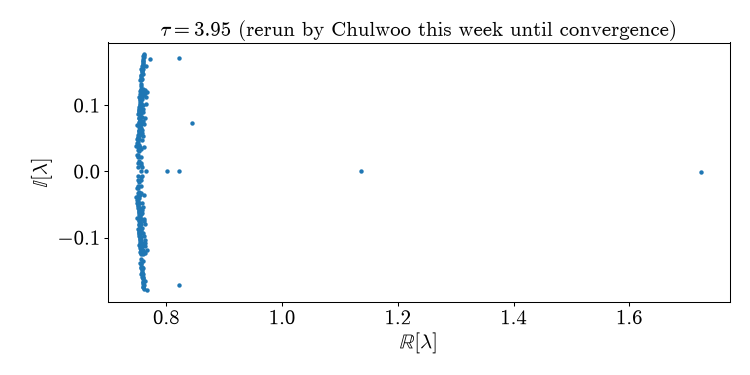

In [43]:
pt.scatter_1d(np.real(evals['3.950000']), np.imag(evals['3.950000']), col = pt.pal[0], fn_label = r'$\tau = 3.95$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'], title = r'$\tau = 3.95$ (rerun by Chulwoo this week until convergence)')

In [44]:
# sm2 = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

# fig, ax = plt.subplots()
# for i, tau in enumerate(tau_window2):
#     pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.8, 2))
# ax.set_ylim((-0.3, 0.3))
# ax.set_title(r'Event 2: Harmonic Krylov-Schur',)

# cbar = fig.colorbar(sm2, ax=ax, label=r"$\tau$")

# tick_taus = ['3.900000', '3.925000', '3.950000', '3.975000', '4.000000']
# cbar.set_ticks([tau_window2.index(t) for t in tick_taus])
# cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

### Event 3: Event precursor at $\tau\approx 3.08$ with no indication of topology change

/var/folders/4q/v1ykxzz94sn6ms0kkh0gm8880000gr/T/ipykernel_48168/2499379660.py:8: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


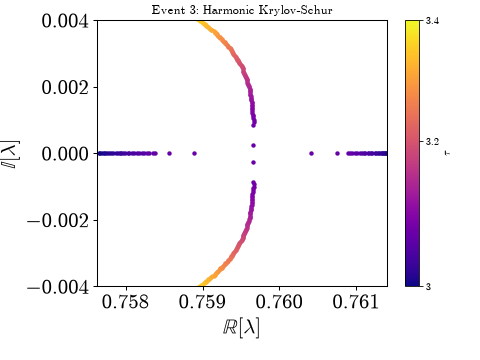

In [45]:
tau_window = [t for t in taus if 3.0 <= float(t) <= 3.4]

# cmap = mpl.colormaps['magma']
cmap = mpl.colormaps['plasma']
norm = mpl.colors.Normalize(vmin=0, vmax=len(tau_window) - 1)
# norm = mpl.colors.PowerNorm(gamma=0.5, vmin=0, vmax=len(tau_window) - 1)

fig, ax = plt.subplots()
for i, tau in enumerate(tau_window):
    pt.scatter_1d(np.real(evals[tau]), np.imag(evals[tau]), ax = ax, col = cmap(norm(i)), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])

# ax.set_xlim((0.757, 0.762))
ax.set_xlim((0.75763, 0.7614))
ax.set_ylim((-0.004, 0.004))
ax.set_title('Event 3: Harmonic Krylov-Schur')

# TODO relabel
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, label=r"$\tau$")

tick_taus = ['3.000000', '3.200000', '3.400000']
cbar.set_ticks([tau_window.index(t) for t in tick_taus])
cbar.set_ticklabels([f"{float(t):g}" for t in tick_taus])

# plt.savefig(f'{FIGS_DIR}/event1.pdf', transparent = True, bbox_inches = 'tight', pad_inches = sty['fig_padding'])

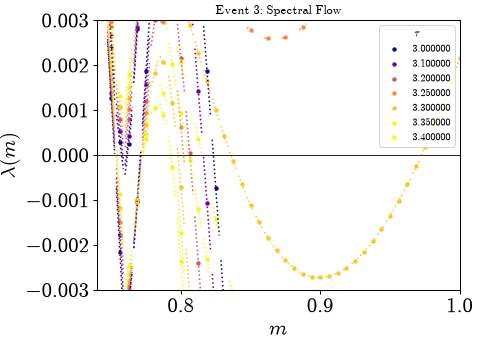

In [46]:
tau_plot3 = ['3.000000', '3.100000', '3.200000', '3.250000', '3.300000', '3.350000', '3.400000']
idx_coarse3 = np.interp(np.array(tau_plot3, dtype=float), np.array(tau_window, dtype=float), np.arange(len(tau_window)))
colors_coarse3 = cmap(norm(idx_coarse3))      # same scale as the HKS plot above

fig, ax = plt.subplots()
plot_specflow(ax, tau_plot3, xlims = (0.74, 1.0), ylims = (-0.003, 0.003), title = r'Event 3: Spectral Flow', cmap = colors_coarse3)

# New Runs (`702_3`)

In [47]:
dir702_3 = r'/Users/patrickoare/Dropbox (Personal)/research/multigrid/wilson_specflow/702_3'
base_3 = Path(dir702_3)

# directories are named U_smr_<tau> or 702_U_smr_<tau>; those without eval_cmplx.final are skipped
evals_3 = {}
for d in base_3.glob('*U_smr_*'):
    f = d / 'eval_cmplx.final'
    if d.is_dir() and f.exists():
        evals_3[d.name.split('U_smr_')[1]] = utils.read_chulwoo_file(f)
taus_3 = sorted(evals_3, key = float)

In [48]:
taus_3

['3.270833',
 '3.272917',
 '3.277083',
 '3.279167',
 '3.462500',
 '3.472917',
 '3.475000',
 '3.487500',
 '3.493750',
 '3.920833',
 '3.922917',
 '3.929167',
 '3.950000',
 '3.954167',
 '3.956250',
 '3.958333',
 '3.960417',
 '3.962500',
 '3.966667',
 '3.968750']

In [49]:
def plot_event_702_3(tau_sf, tau_hks, tau_lims, title, xlims = (0.8, 2.0), ylims_sf = (-0.02, 0.02), ylims_hks = (-0.2, 0.2), M5 = 1.8):
    """Spectral flow (top) and 702_3 HKS eigenvalues (bottom) for one event, on a shared tau color scale."""
    cmap_3 = mpl.colormaps['plasma']
    norm_3 = mpl.colors.Normalize(vmin = tau_lims[0], vmax = tau_lims[1])
    col = lambda tau: cmap_3(norm_3(float(tau)))
    hspace = 0.001

    fig, (ax1, ax2) = plt.subplots(2, 1, sharex = True, layout = 'constrained')
    plot_specflow(ax1, tau_sf, xlims = xlims, ylims = ylims_sf, title = title, cmap = [col(tau) for tau in tau_sf], delta = 0.01, legend = False, dash = True)
    for tau in tau_hks:
        pt.scatter_1d(np.real(evals_3[tau]), np.imag(evals_3[tau]), ax = ax2, col = col(tau), fn_label = r'$\tau = ' + tau + r'$', ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$'])
    fig.set_layout_engine('constrained')
    fig.get_layout_engine().set(hspace = hspace, h_pad = 0)

    ax2.axhline(0, color = 'k', linestyle = '--', lw = 0.8)
    ax2.set_xlim(xlims)
    ax2.set_ylim(ylims_hks)
    for ax in (ax1, ax2):
        if M5 is not None:
            ax.axvline(M5, color = 'k', linestyle = ':', lw = 0.8)
        ax.tick_params(axis = 'x', which = 'both', direction = 'in', bottom = True, top = False)
    ax1.tick_params(axis = 'x', labelbottom = False)
    ax1.set_xlabel('')

    fig.colorbar(mpl.cm.ScalarMappable(norm = norm_3, cmap = cmap_3), ax = [ax1, ax2], label = r'$\tau$', pad = 0.02)
    return fig, (ax1, ax2)

/Users/patrickoare/lqcd/utilities/plottools.py:344: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(
/Users/patrickoare/lqcd/utilities/plottools.py:350: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


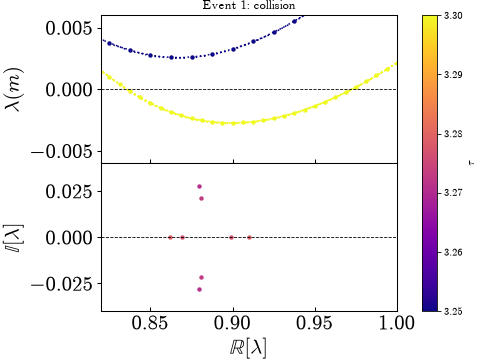

In [50]:
fig, axes = plot_event_702_3(['3.250000', '3.300000'], ['3.270833', '3.272917', '3.277083', '3.279167'], (3.25, 3.30), 'Event 1: collision',
                             xlims = (0.82, 1.0), ylims_sf = (-0.006, 0.006), ylims_hks = (-0.04, 0.04), M5 = None)

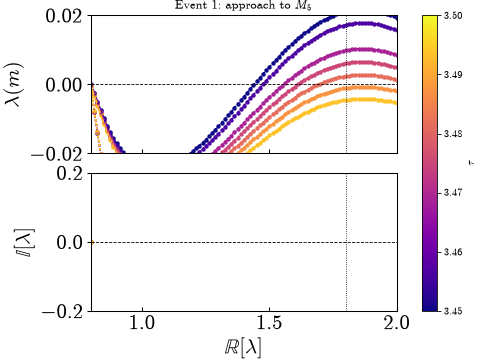

In [51]:
fig, axes = plot_event_702_3(['3.450000', '3.456250', '3.468750', '3.475000', '3.481250', '3.487500', '3.493750'],
                             ['3.462500', '3.472917', '3.475000', '3.487500', '3.493750'], (3.45, 3.50), r'Event 1: approach to $M_5$')

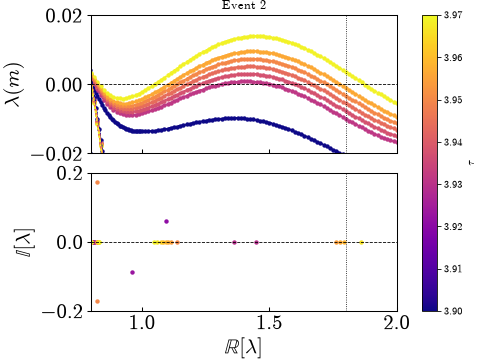

In [52]:
fig, axes = plot_event_702_3(['3.900000', '3.931250', '3.937500', '3.943750', '3.950000', '3.956250', '3.968750'],
                             [t for t in taus_3 if 3.9 <= float(t) <= 4.0], (3.90, 3.97), 'Event 2')

In [53]:
def plot_old_vs_new(tau_lims, title, xlims = (0.8, 2.0), ylims = (-0.2, 0.2), M5 = 1.8):
    """HKS eigenvalues for one event, colored by tau: 702_2 as crosses (1000 iterations where run, otherwise 100) 
    and the 702_3 reruns as filled circles."""
    evals_2 = {**evals, **evals_1000}
    cmap_c = mpl.colormaps['plasma']
    norm_c = mpl.colors.Normalize(vmin = tau_lims[0], vmax = tau_lims[1])
    col = lambda tau: cmap_c(norm_c(float(tau)))
    in_window = lambda tau: tau_lims[0] <= float(tau) <= tau_lims[1]
    ax_label = [r'$\mathbb{R}[\lambda]$', r'$\mathbb{I}[\lambda]$']

    fig, ax = plt.subplots(layout = 'constrained')
    for tau in filter(in_window, taus_3):
        pt.scatter_1d(np.real(evals_3[tau]), np.imag(evals_3[tau]), ax = ax, col = col(tau), mkr = 'x', fn_label = '_nolegend_', ax_label = ax_label)
    for tau in filter(in_window, taus):
        pt.scatter_1d(np.real(evals_2[tau]), np.imag(evals_2[tau]), ax = ax, col = col(tau), fn_label = '_nolegend_', ax_label = ax_label, linewidths = 1, zorder = 3)
    fig.set_layout_engine('constrained')

    ax.axhline(0, color = 'k', linestyle = '--', lw = 0.8)
    if M5 is not None:
        ax.axvline(M5, color = 'k', linestyle = ':', lw = 0.8)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_title(title)

    # marker key in black, since color encodes tau
    ax.scatter([], [], marker = '.', color = 'k', linewidths = 1, label = r'$\mathtt{702\_2}$')
    ax.scatter([], [], marker = 'x', color = 'k', label = r'$\mathtt{702\_3}$')
    ax.legend(loc = 'upper right')
    fig.colorbar(mpl.cm.ScalarMappable(norm = norm_c, cmap = cmap_c), ax = ax, label = r'$\tau$', pad = 0.02)
    return fig, ax

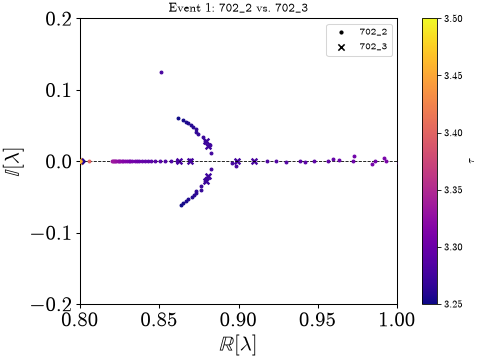

In [54]:
# fig, ax = plot_old_vs_new((3.25, 3.50), r'Event 1: $\mathtt{702\_2}$ vs. $\mathtt{702\_3}$')
fig, ax = plot_old_vs_new((3.25, 3.50), r'Event 1: $\mathtt{702\_2}$ vs. $\mathtt{702\_3}$', xlims = (0.8, 1.0))

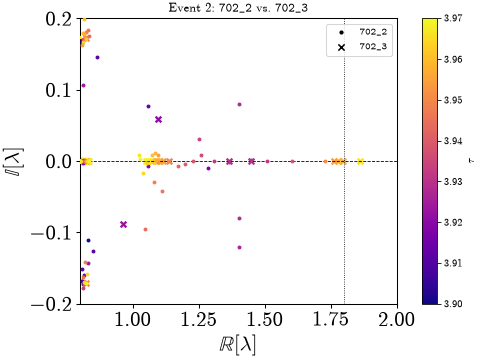

In [55]:
fig, ax = plot_old_vs_new((3.90, 3.97), r'Event 2: $\mathtt{702\_2}$ vs. $\mathtt{702\_3}$')